# Task 0 — Polynomial power model

Converted from `task0.py`. Run cells from top to bottom. Place this notebook in the project root, next to the `data/` directory. The original selection tolerance is **1%**.

## Setup and data loading

In [1]:
from pathlib import Path 
import pandas as pd
from sklearn.linear_model import LinearRegression, LassoCV
from sklearn.model_selection import KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from kneed import KneeLocator
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import matplotlib.pyplot as plt

# Main paths:
root_p = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
data_p = root_p / 'data'

case1_p = data_p/'case1'
test1_p = case1_p/'test1.csv'
train1_p = case1_p/'train1.csv'

# Main data frames:
test1 = pd.read_csv(test1_p)
train1 = pd.read_csv(train1_p)

# Adding KRPM column:
test1['speed_krpm'] = test1['speed_rpm'] / 1000
train1['speed_krpm'] = train1['speed_rpm'] / 1000

## Polynomial features

In [2]:
# Polynomial features for training and testing:
train_features = pd.DataFrame(index=train1.index)
test_features = pd.DataFrame(index=test1.index)
for i in range(4):
    for j in range(4):
        if i == 0 and j == 0:
            continue  # The constant term is handled by the intercept when enabled
        feature = f'n{i}_Q{j}'
        train_features[feature] = train1['speed_krpm']**i * train1['flow_m3_h']**j
        test_features[feature] = test1['speed_krpm']**i * test1['flow_m3_h']**j

X = train_features
y = train1['power_w']
y_test = test1['power_w']
cv = KFold(n_splits=5, shuffle=True, random_state=42)

## Feature-selection functions

In [3]:
# Forward feature selection for both models using training CV:
def forward_selection(estimator):
    selected = []
    remaining = list(X.columns)
    best_rmse = float('inf')

    while remaining:
        candidate_scores = []
        for feature in remaining:
            candidate = selected + [feature]
            scores = cross_val_score(
                estimator, X[candidate], y,
                cv=cv, scoring='neg_root_mean_squared_error'
            )
            candidate_scores.append((-scores.mean(), feature))

        candidate_rmse, candidate_feature = min(candidate_scores)
        if candidate_rmse >= best_rmse:
            break

        selected.append(candidate_feature)
        remaining.remove(candidate_feature)
        best_rmse = candidate_rmse

    return selected, best_rmse

# Score feature subsets with CV RMSE, AIC, or BIC:
def selection_score(features, estimator, criterion):
    if criterion == 'CV RMSE':
        return -cross_val_score(estimator, X[features], y, cv=cv,
                                scoring='neg_root_mean_squared_error').mean()
    fitted = LinearRegression(fit_intercept=estimator.fit_intercept).fit(X[features], y)
    rss = np.sum((y - fitted.predict(X[features]))**2)
    n = len(y)
    k = len(features) + int(estimator.fit_intercept)
    penalty = 2 * k if criterion == 'AIC' else np.log(n) * k
    return n * np.log(max(rss / n, np.finfo(float).tiny)) + penalty

# Backward CV RMSE and forward/backward AIC and BIC:
def stepwise_selection(estimator, direction, criterion):
    selected = [] if direction == 'forward' else list(X.columns)
    best = float('inf') if direction == 'forward' else selection_score(selected, estimator, criterion)
    while (len(selected) < len(X.columns) if direction == 'forward' else len(selected) > 1):
        options = ([name for name in X.columns if name not in selected]
                   if direction == 'forward' else selected)
        candidates = []
        for name in options:
            subset = (selected + [name] if direction == 'forward'
                      else [feature for feature in selected if feature != name])
            candidates.append((selection_score(subset, estimator, criterion), name))
        score, name = min(candidates)
        if score >= best:
            break
        if direction == 'forward':
            selected.append(name)
        else:
            selected.remove(name)
        best = score
    return selected

# Full greedy forward path: yields both Forward CV RMSE and Elbow selections
def forward_and_elbow_selection(estimator):
    selected = []
    errors = []
    while len(selected) < len(X.columns):
        remaining = [name for name in X.columns if name not in selected]
        scored = [
            (selection_score(selected + [name], estimator, 'CV RMSE'), name)
            for name in remaining
        ]
        best_step_rmse, best_name = min(scored)
        selected.append(best_name)
        errors.append(best_step_rmse)

    # 1. Forward CV RMSE: stop right before the first step where error stops improving
    stop_idx = len(errors)
    for i in range(1, len(errors)):
        if errors[i] >= errors[i - 1]:
            stop_idx = i
            break
    forward_features = selected[:stop_idx]
    forward_rmse = errors[stop_idx - 1]

    # 2. Elbow: detect the bend along the full greedy forward path
    knee = KneeLocator(range(1, len(errors) + 1), errors,
                       curve='convex', direction='decreasing')
    elbow_count = int(knee.knee) if knee.knee is not None else int(np.argmin(errors)) + 1
    elbow_features = selected[:elbow_count]
    elbow_rmse = errors[elbow_count - 1]

    return (forward_features, forward_rmse), (elbow_features, elbow_rmse)

## Run feature selection

In [4]:
# Feature selection:
lasso_models = {}
selection_results = []
for model_name, fit_intercept in [('Original', True), ('Zero intercept', False)]:
    estimator = LinearRegression(fit_intercept=fit_intercept)

    (fwd_features, fwd_rmse), (elbow_features, elbow_rmse) = forward_and_elbow_selection(estimator)
    selection_results.append((model_name, 'Forward CV RMSE', fwd_features, fwd_rmse))
    selection_results.append((model_name, 'Elbow', elbow_features, elbow_rmse))

    for criterion in ['CV RMSE', 'AIC', 'BIC']:
        for direction in ['forward', 'backward']:
            if criterion == 'CV RMSE' and direction == 'forward':
                continue
            features = stepwise_selection(estimator, direction, criterion)
            rmse = selection_score(features, estimator, 'CV RMSE')
            selection_results.append((model_name, f'{direction.title()} {criterion}', features, rmse))

    # Standardize predictors before Lasso; do not center for zero-intercept fits.
    lasso = make_pipeline(
        StandardScaler(with_mean=fit_intercept),
        LassoCV(cv=cv, fit_intercept=fit_intercept, random_state=42, max_iter=100000)
    )
    lasso.fit(X, y)
    lasso_models[model_name] = lasso
    features = list(X.columns[np.abs(lasso.named_steps['lassocv'].coef_) > 1e-8])
    if features:
        rmse = np.sqrt(np.min(np.mean(lasso.named_steps['lassocv'].mse_path_, axis=1)))
        selection_results.append((model_name, 'LassoCV', features, rmse))

# Print feature selection results:
print('\nFeature selection results:')
for model_name, method, features, cv_rmse in selection_results:
    print(f'\n{model_name} | {method}')
    print('Selected features:', features)
    print(f'Number of features: {len(features)}')
    print(f'5-fold CV RMSE: {cv_rmse:.4f} W')


Feature selection results:

Original | Forward CV RMSE
Selected features: ['n3_Q0', 'n2_Q1', 'n0_Q3', 'n1_Q2']
Number of features: 4
5-fold CV RMSE: 10.3982 W

Original | Elbow
Selected features: ['n3_Q0', 'n2_Q1', 'n0_Q3']
Number of features: 3
5-fold CV RMSE: 11.4780 W

Original | Backward CV RMSE
Selected features: ['n0_Q1', 'n0_Q2', 'n0_Q3', 'n1_Q1', 'n1_Q2', 'n1_Q3', 'n2_Q2', 'n2_Q3', 'n3_Q0', 'n3_Q1', 'n3_Q2', 'n3_Q3']
Number of features: 12
5-fold CV RMSE: 10.4436 W

Original | Forward AIC
Selected features: ['n3_Q0', 'n2_Q1', 'n0_Q3', 'n1_Q2']
Number of features: 4
5-fold CV RMSE: 10.3982 W

Original | Backward AIC
Selected features: ['n0_Q1', 'n0_Q2', 'n0_Q3', 'n1_Q1', 'n1_Q2', 'n1_Q3', 'n2_Q2', 'n2_Q3', 'n3_Q0', 'n3_Q1', 'n3_Q2', 'n3_Q3']
Number of features: 12
5-fold CV RMSE: 10.4436 W

Original | Forward BIC
Selected features: ['n3_Q0', 'n2_Q1', 'n0_Q3', 'n1_Q2']
Number of features: 4
5-fold CV RMSE: 10.3982 W

Original | Backward BIC
Selected features: ['n0_Q1', 'n1_Q1', 

## Fit and evaluate models

In [5]:
# Model fitting: train each selected model on all training data:
fitted_models = []
for model_name, method, features, cv_rmse in selection_results:
    if method == 'LassoCV':
        fitted = lasso_models[model_name]
    else:
        fitted = LinearRegression(fit_intercept=model_name == 'Original')
        fitted.fit(X[features], y)

    fitted_models.append({
        'model': model_name,
        'method': method,
        'features': features,
        'estimator': fitted,
        'cv_rmse': cv_rmse
    })

# Test evaluation: calculate metrics using the held-out test data:
print('\nTest evaluation results:')
for result in fitted_models:
    features = result['features']
    fitted = result['estimator']
    if result['method'] == 'LassoCV':
        predictions = fitted.predict(test_features)
    else:
        predictions = fitted.predict(test_features[features])

    errors = y_test - predictions
    result['test_rmse'] = np.sqrt(mean_squared_error(y_test, predictions))
    result['test_mae'] = mean_absolute_error(y_test, predictions)
    result['test_r2'] = r2_score(y_test, predictions)
    result['test_max_absolute_error'] = np.max(np.abs(errors))

    print(f"\n{result['model']} | {result['method']}")
    print(f"Number of features: {len(features)}")
    print(f"Test RMSE: {result['test_rmse']:.4f} W")
    print(f"Test MAE: {result['test_mae']:.4f} W")
    print(f"Test R²: {result['test_r2']:.4f}")
    print(f"Max absolute error: {result['test_max_absolute_error']:.4f} W")


Test evaluation results:

Original | Forward CV RMSE
Number of features: 4
Test RMSE: 10.3587 W
Test MAE: 8.0630 W
Test R²: 0.9996
Max absolute error: 37.6427 W

Original | Elbow
Number of features: 3
Test RMSE: 10.9294 W
Test MAE: 8.3444 W
Test R²: 0.9996
Max absolute error: 34.1238 W

Original | Backward CV RMSE
Number of features: 12
Test RMSE: 10.3912 W
Test MAE: 8.0486 W
Test R²: 0.9996
Max absolute error: 37.5172 W

Original | Forward AIC
Number of features: 4
Test RMSE: 10.3587 W
Test MAE: 8.0630 W
Test R²: 0.9996
Max absolute error: 37.6427 W

Original | Backward AIC
Number of features: 12
Test RMSE: 10.3912 W
Test MAE: 8.0486 W
Test R²: 0.9996
Max absolute error: 37.5172 W

Original | Forward BIC
Number of features: 4
Test RMSE: 10.3587 W
Test MAE: 8.0630 W
Test R²: 0.9996
Max absolute error: 37.6427 W

Original | Backward BIC
Number of features: 9
Test RMSE: 10.4997 W
Test MAE: 8.0457 W
Test R²: 0.9996
Max absolute error: 38.1123 W

Original | LassoCV
Number of features: 8
T

## Choose models

In [6]:
# Select the simplest model within 1% of the best CV RMSE for each intercept case:
selected_models = {}
for model_name in ['Original', 'Zero intercept']:
    candidates = [result for result in fitted_models if result['model'] == model_name]
    best_cv_rmse = min(result['cv_rmse'] for result in candidates)
    eligible = [result for result in candidates if result['cv_rmse'] <= 1.01 * best_cv_rmse]
    selected = min(eligible, key=lambda result: (len(result['features']), result['cv_rmse']))
    selected_models[model_name] = selected

    print(f'\nSelected model: {model_name}')
    print(f"Method: {selected['method']}")
    print(f"Features: {selected['features']}")
    print(f"Number of features: {len(selected['features'])}")
    print(f"CV RMSE: {selected['cv_rmse']:.4f} W")
    print(f"Test RMSE: {selected['test_rmse']:.4f} W")
    print(f"Test MAE: {selected['test_mae']:.4f} W")
    print(f"Test R²: {selected['test_r2']:.4f}")
    print(f"Max absolute error: {selected['test_max_absolute_error']:.4f} W")


Selected model: Original
Method: Forward CV RMSE
Features: ['n3_Q0', 'n2_Q1', 'n0_Q3', 'n1_Q2']
Number of features: 4
CV RMSE: 10.3982 W
Test RMSE: 10.3587 W
Test MAE: 8.0630 W
Test R²: 0.9996
Max absolute error: 37.6427 W

Selected model: Zero intercept
Method: Backward BIC
Features: ['n0_Q3', 'n1_Q0', 'n1_Q2', 'n2_Q0', 'n2_Q1', 'n3_Q0']
Number of features: 6
CV RMSE: 10.3703 W
Test RMSE: 10.3580 W
Test MAE: 8.0331 W
Test R²: 0.9996
Max absolute error: 37.9984 W


## Residuals vs flow and speed

In [7]:
# Print the exact learned polynomial equations for both selected models:
for model_name, selected in selected_models.items():
    fitted = selected['estimator']
    features = selected['features']
    if selected['method'] == 'LassoCV':
        scaler = fitted.named_steps['standardscaler']
        lasso_cv = fitted.named_steps['lassocv']
        # Unscale coefficients back to raw polynomial units:
        raw_coefs = lasso_cv.coef_ / scaler.scale_
        intercept = (
            lasso_cv.intercept_ - np.sum(raw_coefs * scaler.mean_)
            if model_name == 'Original' else 0.0
        )
        terms = [f"{c:+.4f}*{f}" for f, c in zip(X.columns, raw_coefs) if abs(c) > 1e-8]
    else:
        coefs = fitted.coef_
        intercept = fitted.intercept_ if model_name == 'Original' else 0.0
        terms = [f"{c:+.4f}*{f}" for f, c in zip(features, coefs)]

    eq = f"P = {intercept:.4f} " + " ".join(terms)
    print(f"\n{model_name} Equation:\n{eq}")


Original Equation:
P = 40.8650 +7.6578*n3_Q0 +2.4072*n2_Q1 -0.0084*n0_Q3 -0.0496*n1_Q2

Zero intercept Equation:
P = 0.0000 -0.0084*n0_Q3 +42.1040*n1_Q0 -0.0495*n1_Q2 -13.4527*n2_Q0 +2.4073*n2_Q1 +9.0132*n3_Q0


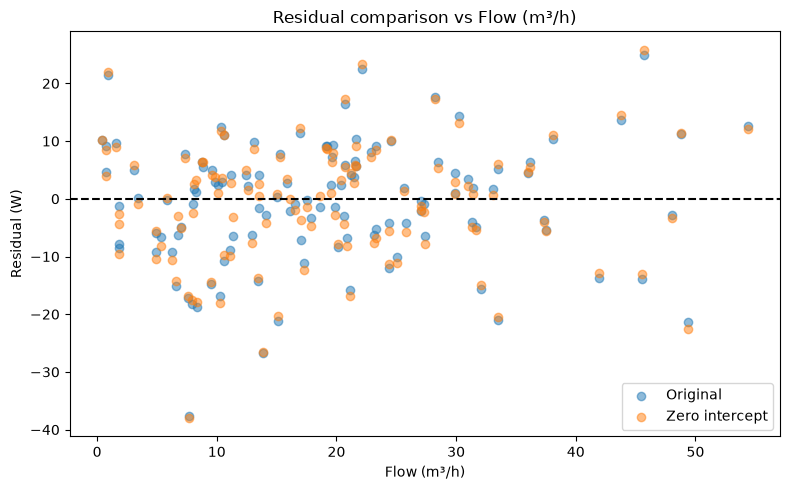

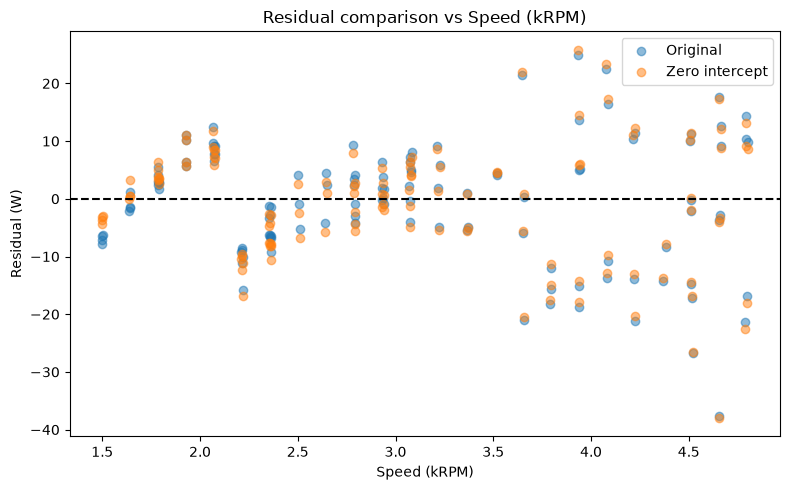

In [8]:
# Compare both selected intercept cases on the same residual plots:
residuals_by_model = {}
predictions_by_model = {}
for model_name, selected in selected_models.items():
    fitted = selected['estimator']
    features = selected['features']
    preds = (fitted.predict(test_features) if selected['method'] == 'LassoCV'
             else fitted.predict(test_features[features]))
    predictions_by_model[model_name] = preds
    residuals_by_model[model_name] = y_test - preds

for column, xlabel, fname in [
    ('flow_m3_h', 'Flow (m³/h)', 'task0_residuals_vs_flow.png'),
    ('speed_krpm', 'Speed (kRPM)', 'task0_residuals_vs_speed.png')
]:
    plt.figure(figsize=(8, 5))
    for model_name, residuals in residuals_by_model.items():
        plt.scatter(test1[column], residuals, alpha=0.5, label=model_name)
    plt.axhline(0, color='black', linestyle='--')
    plt.xlabel(xlabel)
    plt.ylabel('Residual (W)')
    plt.title(f'Residual comparison vs {xlabel}')
    plt.legend()
    plt.tight_layout()
    plt.show()

## Predicted vs actual power

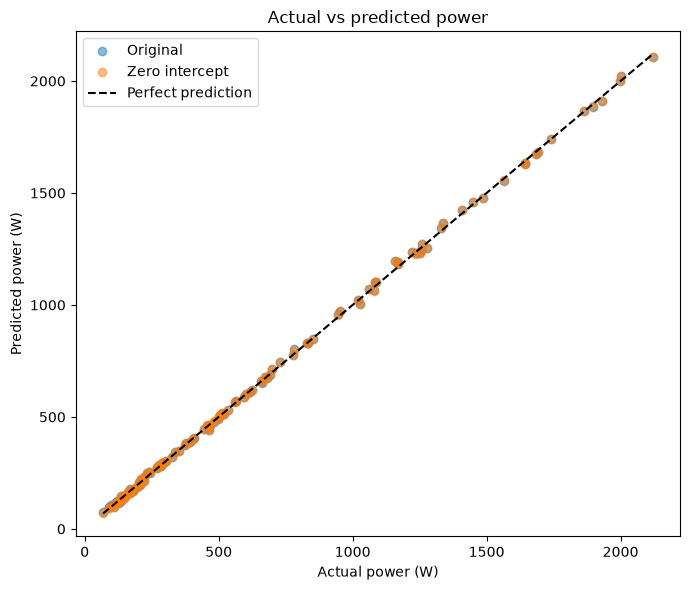

In [9]:
# Actual vs predicted power (both models):
plt.figure(figsize=(7, 6))
for model_name, predictions in predictions_by_model.items():
    plt.scatter(y_test, predictions, alpha=0.5, label=model_name)
limits = [min(y_test.min(), *(p.min() for p in predictions_by_model.values())),
          max(y_test.max(), *(p.max() for p in predictions_by_model.values()))]
plt.plot(limits, limits, 'k--', label='Perfect prediction')
plt.xlabel('Actual power (W)')
plt.ylabel('Predicted power (W)')
plt.title('Actual vs predicted power')
plt.legend()
plt.tight_layout()
plt.show()

## CV RMSE vs complexity

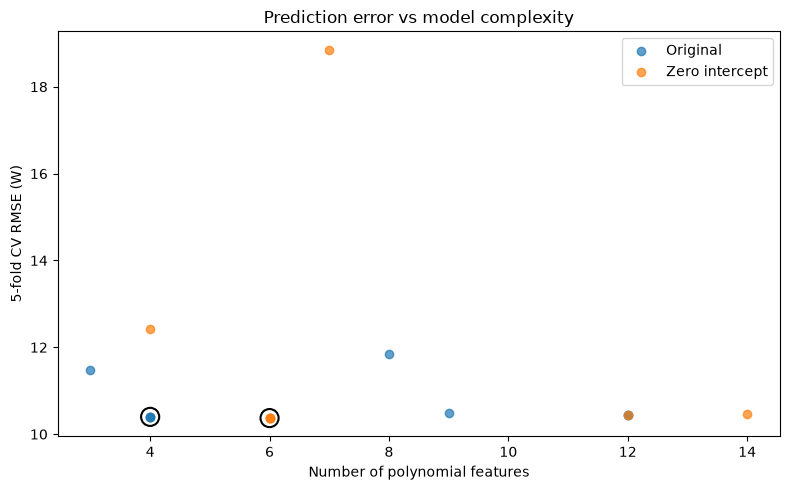

In [10]:
# CV RMSE vs number of features (all selection methods):
plt.figure(figsize=(8, 5))
for model_name in selected_models:
    candidates = [result for result in fitted_models if result['model'] == model_name]
    plt.scatter([len(result['features']) for result in candidates],
                [result['cv_rmse'] for result in candidates],
                alpha=0.7, label=model_name)
    selected = selected_models[model_name]
    plt.scatter(len(selected['features']), selected['cv_rmse'],
                s=170, facecolors='none', edgecolors='black', linewidths=1.5)
plt.xlabel('Number of polynomial features')
plt.ylabel('5-fold CV RMSE (W)')
plt.title('Prediction error vs model complexity')
plt.legend()
plt.tight_layout()
plt.show()

## Residual distributions

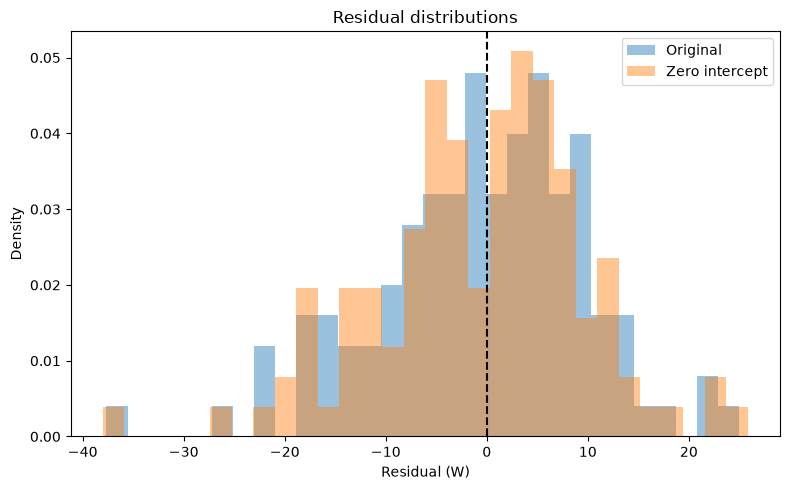

In [11]:
# Residual distributions (both models):
plt.figure(figsize=(8, 5))
for model_name, residuals in residuals_by_model.items():
    plt.hist(residuals, bins=30, alpha=0.45, density=True, label=model_name)
plt.axvline(0, color='black', linestyle='--')
plt.xlabel('Residual (W)')
plt.ylabel('Density')
plt.title('Residual distributions')
plt.legend()
plt.tight_layout()
plt.show()

## Residuals vs predicted power

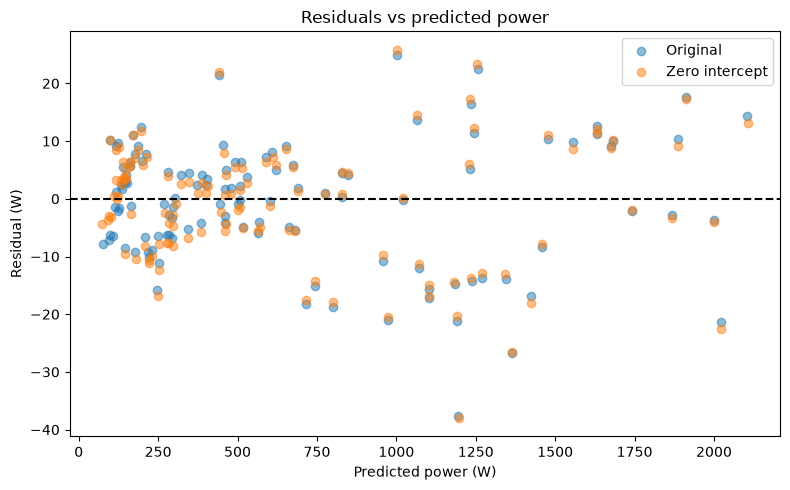

In [12]:
# Residuals vs predicted power (both models):
plt.figure(figsize=(8, 5))
for model_name, predictions in predictions_by_model.items():
    plt.scatter(predictions, residuals_by_model[model_name],
                alpha=0.5, label=model_name)
plt.axhline(0, color='black', linestyle='--')
plt.xlabel('Predicted power (W)')
plt.ylabel('Residual (W)')
plt.title('Residuals vs predicted power')
plt.legend()
plt.tight_layout()
plt.show()